In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
from pygam import LinearGAM, s
import matplotlib.pyplot as plt

/home/caleb/miniconda3/envs/pygam/lib/python3.13/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3


In [7]:
pth_data = os.path.join('..', 'data')
pth_in = os.path.join(pth_data, 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join('..', 'figures', 'preprocessing')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata.obs['t'] = adata.obs.t.astype(float); adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 't', 'source'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj'

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
for src, df_src in feat_dict.items():
    print(src)
    g = df_src.mmusculus.copy()
    g = g.loc[g.isin(adata.var_names)]
    for _, df_group in adata.obs.groupby('source', observed = True):
        msk = adata.obs_names.isin(df_group.index)
        adata_group = adata[msk].copy()
        sc.tl.score_genes(adata_group,
                          gene_list = g,
                          ctrl_as_ref = False,
                          score_name = src,
                          random_state = 1234)
        adata.obs.loc[msk, src] = adata_group.obs[src]

GSE162534
GSE229103
rRNAModifications


In [5]:
def fit_gam(Y, X, n_spl, n_pts):
    GAM = LinearGAM(s(0, n_splines = n_spl))
    GAM = GAM.fit(X, scale_01(Y))
    xx = np.linspace(X.min(), X.max(), n_pts)
    return scale_01(GAM.predict(xx))

def scale_01(Y):
    return (Y - Y.min()) / (Y.max() - Y.min())

In [6]:
labels_dict = {
    'GSE162534'         : 'PS',
    'GSE229103'         : 'NMP',
    'rRNAModifications' : 'CNCC'}

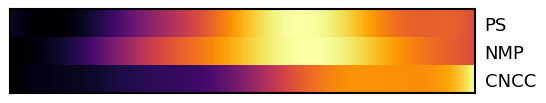

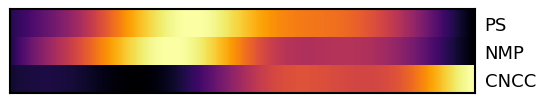

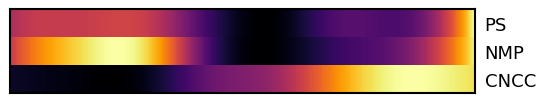

In [78]:
# signatures trends (GAMs)
n_pts, n_spl, cols = 500, 10, list(feat_dict.keys())
for src, sdf in adata.obs.groupby('source', observed = True):

    # fit GAMs
    X = np.zeros((len(cols), n_pts))
    for i, mod in enumerate(cols):
        X[i] = fit_gam(sdf[mod], sdf.t, n_spl, n_pts)

    # plot heatmap
    fig, ax = plt.subplots(1, 1, figsize = (6, 3))
    ax.imshow(X, aspect = 30, interpolation = 'nearest', cmap = 'inferno')
    yticklabels = [labels_dict[mod] for mod in cols]
    ax.set_yticks(np.arange(len(cols)), yticklabels, fontsize = 13)
    ax.tick_params('y', left = False, labelleft = False, labelright = True)
    ax.set_xticks([])
    for sp in ax.spines.values(): sp.set_linewidth(1.5)
    fn = os.path.join(pth_fig, 'modules', f'{src}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

In [ ]:
# To-Do: save modules for modeling